# Evaluación de lenguaje ciudadano

Este notebook evalúa la capacidad del asistente para interpretar consultas ciudadanas relacionadas con la contratación pública. Se utilizan 51 expresiones de desarrollo para analizar el reconocimiento de intenciones, la interpretación de preguntas y el comportamiento ante solicitudes ambiguas o no soportadas. Las 26 expresiones restantes se reservan para una validación posterior.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

aqui = Path.cwd().resolve()
RAIZ = next(
    (
        c
        for c in (aqui, *aqui.parents)
        if (c / "src" / "rag").is_dir() and (c / "notebooks").is_dir()
    ),
    None,
)
if RAIZ is None:
    raise FileNotFoundError("Ejecute el notebook desde el repositorio secop-tfm.")
sys.path.insert(0, str(RAIZ / "src"))

from nlq_eval.capacidades import CAPACIDADES
from nlq_eval.cliente import diagnosticar_chat
from nlq_eval.evaluar import evaluar_linea_base, evaluar_v2
from nlq_eval.particion import IDS_RESERVADOS, cargar_excel, partir
from nlq_eval.rutas import ruta_excel, ruta_salidas_nlq

SALIDAS = ruta_salidas_nlq()
print("Excel:", ruta_excel(), ruta_excel().is_file())
print("Salidas:", SALIDAS)
print("Reservados:", len(IDS_RESERVADOS))


Excel: /home/jovyan/work/data/corpus/originales/expresiones_ciudadanas_simuladas_TFM.xlsx True
Salidas: /home/jovyan/work/spark-apps/notebooks/salidas/nlq
Reservados: 26


## 1. Capacidades reales del asistente

Se identifican las funcionalidades disponibles en el asistente, considerando las consultas analíticas, los filtros, las intenciones reconocidas y las operaciones no soportadas. Esta revisión permite establecer los criterios de referencia para evaluar las respuestas.

In [2]:
print(json.dumps(CAPACIDADES, ensure_ascii=False, indent=2))

{
  "periodo": "2026-09",
  "territorio_filtro": "solo bogota (es_bogota = sede de la entidad, no lugar de ejecución)",
  "operaciones_nlq": [
    "contar",
    "ranking",
    "distribucion"
  ],
  "metricas_nlq": [
    "n_contratos",
    "valor"
  ],
  "filtros_nlq": [
    "territorio=bogota",
    "entidad (resolución por nombre)",
    "modalidad (pista léxica)"
  ],
  "intenciones_cerradas": [
    "BOGOTA_CONTRATACION",
    "TOP_ENTIDADES",
    "MODALIDADES",
    "TOP1_IF",
    "PORQUE_ATIPICO",
    "EXPLAIN_CONTRACT",
    "TOP_PROVIDERS",
    "INVESTMENT_CITY",
    "EXECUTION_TIME_ENTITY",
    "LONGEST_CONTRACTS",
    "RISK_ANALYSIS",
    "NLQ",
    "NO_SOPORTADO",
    "UNKNOWN"
  ],
  "especiales_sin_filtro_extra": [
    "TOP1_IF",
    "TOP_PROVIDERS",
    "INVESTMENT_CITY",
    "EXECUTION_TIME_ENTITY",
    "LONGEST_CONTRACTS",
    "RISK_ANALYSIS"
  ],
  "no_soportado_hoy": [
    "RAG documental en POST /api/chat",
    "listado de contratos por entidad o modalidad",
    "filtro de 

## 2. Excel y partición 51 / 26

Se carga el conjunto de 77 expresiones ciudadanas y se divide en 51 preguntas y 26 reservadas para validación. Se verifica la distribución por categorías y se garantiza que las preguntas reservadas no participen en la evaluación inicial.

In [3]:
filas = cargar_excel()
part = partir(filas)
assert part["n_excel"] == 77, part["n_excel"]
assert part["n_desarrollo"] == 51, part["n_desarrollo"]
assert part["n_reservadas"] == 26, part["n_reservadas"]
assert not part["faltan_reservados"], part["faltan_reservados"]
assert set(part["ids_reservadas"]) == set(IDS_RESERVADOS)
print("n Excel", part["n_excel"], "desarrollo", part["n_desarrollo"], "reservadas", part["n_reservadas"])
print("Categorías:", json.dumps(part["categorias"], ensure_ascii=False))
print("IDs reservados:", part["ids_reservadas"])
display(pd.DataFrame(part["desarrollo"])[["id", "categoria", "pregunta", "intencion_excel"]].head(8))


n Excel 77 desarrollo 51 reservadas 26
Categorías: {"Cantidad de contratos": 6, "Valores y montos": 6, "Modalidades": 6, "Expresiones coloquiales": 6, "Entidades": 6, "Proveedores": 6, "Anomalías": 6, "Riesgo y afirmaciones delicadas": 5, "Conceptos y normativa": 6, "Explicación de modelos": 6, "Seguimiento conversacional": 6, "Ambigüedad y cobertura": 6, "Datos y calidad": 6}
IDs reservados: ['EC-005', 'EC-006', 'EC-011', 'EC-012', 'EC-017', 'EC-018', 'EC-023', 'EC-024', 'EC-029', 'EC-030', 'EC-035', 'EC-036', 'EC-041', 'EC-042', 'EC-046', 'EC-047', 'EC-052', 'EC-053', 'EC-058', 'EC-059', 'EC-064', 'EC-065', 'EC-070', 'EC-071', 'EC-076', 'EC-077']


,id,categoria,pregunta,intencion_excel
0,EC-001,Cantidad de contratos,¿Cuántos contratos hicieron en Bogotá en septi...,contar_contratos
1,EC-002,Cantidad de contratos,¿Cuántos contratos hubo el mes pasado?,contar_contratos
2,EC-003,Cantidad de contratos,¿Cuántos contratos se firmaron en septiembre?,contar_contratos
3,EC-004,Cantidad de contratos,Dime el número de contratos de Bogotá,contar_contratos
4,EC-007,Valores y montos,¿Cuánta plata contrataron en Bogotá?,sumar_valores
5,EC-008,Valores y montos,¿Cuánto se gastó en contratos durante septiembre?,sumar_valores
6,EC-009,Valores y montos,¿Cuál fue el valor total contratado?,sumar_valores
7,EC-010,Valores y montos,¿Cuánta plata movió esa entidad?,sumar_valores


## 3. Probar conectividad

Se verifica la comunicación con la API del asistente mediante una consulta de prueba. Esta comprobación permite confirmar la disponibilidad del servicio antes de ejecutar la evaluación

In [4]:
diag = diagnosticar_chat()
print(json.dumps(diag, ensure_ascii=False, indent=2))
if not diag["disponible"]:
    print("BLOQUEO: el asistente no responde desde este contenedor.")


{
  "disponible": true,
  "url": "http://orchestration-layer:3000/api/chat",
  "intentos": [
    {
      "url": "http://orchestration-layer:3000/api/chat",
      "status": 200,
      "segundos": 0.082,
      "ok": true,
      "intent": "BOGOTA_CONTRATACION",
      "claves": [
        "data",
        "description",
        "intent",
        "slots",
        "text",
        "visualization"
      ]
    }
  ]
}


## 4. Línea base (51 preguntas, un turno, sin contexto)

Se envían las 51 expresiones al asistente de manera independiente y sin contexto conversacional. Se evalúa la interpretación de cada pregunta, el reconocimiento de la intención y la capacidad para responder, solicitar aclaraciones o identificar consultas no soportadas.

In [5]:
salida = evaluar_linea_base(salidas=SALIDAS)
print("bloqueo", salida["bloqueo"])
met = salida["metricas"]
print(json.dumps({k: met[k] for k in met if k not in {"capacidades", "diagnostico", "ids_ok", "ids_error"}}, ensure_ascii=False, indent=2))


bloqueo False
{
  "generado_utc": "2026-11-02T22:45:54Z",
  "version": "v1_linea_base",
  "aviso": "Línea base del prototipo actual, sin glosario ni cambios de NLQ. Las 26 EC reservadas no se usaron. No es validación final.",
  "n_excel": 77,
  "n_desarrollo": 51,
  "n_reservadas": 26,
  "n_evaluadas": 51,
  "n_infra": 0,
  "n_validas": 51,
  "url": "http://orchestration-layer:3000/api/chat",
  "exactitud_interpretacion": 0.451,
  "exactitud_intencion": 0.6667,
  "exactitud_filtros": 1.0,
  "exactitud_comportamiento": 0.5294,
  "pct_aclaraciones_adecuadas": 0.4211,
  "pct_rechazo_correcto": 0.0833,
  "n_riesgo_enganoso": 11,
  "n_esperado_ejecutar": 20,
  "n_esperado_aclarar": 19,
  "n_esperado_rechazar": 12,
  "segundos_medio": 0.641,
  "errores_por_tipo": {
    "ejecucion": 10,
    "intencion": 15,
    "no_implementada": 2
  },
  "matriz_confusion_comportamiento": {
    "ejecutar": {
      "ejecutar": 18,
      "aclarar": 2,
      "rechazar": 0,
      "error_infra": 0
    },
    "acl

## 5. Etiquetas de referencia y resultados por expresión

Se comparan las respuestas del asistente con las etiquetas de referencia definidas según sus capacidades. Se revisan las intenciones identificadas, los comportamientos observados, los errores de interpretación y los posibles riesgos de información engañosa.

In [6]:
if salida["bloqueo"]:
    print("Sin resultados: el chat no está disponible.")
else:
    ref = salida["referencia"]
    res = salida["resultados"]
    display(ref[["id", "categoria", "pregunta", "intencion_esperada", "comportamiento_esperado", "capacidad", "justificacion"]])
    display(res[["id", "intent_observado", "tipo_respuesta", "interpretacion_ok", "tipo_error", "riesgo_enganoso", "segundos", "texto"]])


,id,categoria,pregunta,intencion_esperada,comportamiento_esperado,capacidad,justificacion
0,EC-001,Cantidad de contratos,¿Cuántos contratos hicieron en Bogotá en septi...,BOGOTA_CONTRATACION,ejecutar,soportada,Cuántos + Bogotá + septiembre. NLQ cuenta con ...
1,EC-002,Cantidad de contratos,¿Cuántos contratos hubo el mes pasado?,NO_SOPORTADO,aclarar,requiere_aclaracion,«El mes pasado» no es un periodo del prototipo...
2,EC-003,Cantidad de contratos,¿Cuántos contratos se firmaron en septiembre?,NLQ,ejecutar,soportada,Septiembre sí; no nombra ciudad. No se inventa...
3,EC-004,Cantidad de contratos,Dime el número de contratos de Bogotá,BOGOTA_CONTRATACION,ejecutar,soportada,Número de contratos de Bogotá. Territorio bast...
4,EC-007,Valores y montos,¿Cuánta plata contrataron en Bogotá?,NLQ,ejecutar,soportada,«Plata» debería mapear a valor contratado en B...
5,EC-008,Valores y montos,¿Cuánto se gastó en contratos durante septiembre?,NLQ,ejecutar,parcial,«Gastó» activa valor; no hay gasto ejecutado d...
6,EC-009,Valores y montos,¿Cuál fue el valor total contratado?,NLQ,ejecutar,soportada,"Valor total contratado del periodo publicado, ..."
7,EC-010,Valores y montos,¿Cuánta plata movió esa entidad?,NO_SOPORTADO,aclarar,requiere_aclaracion,«Esa entidad» sin turno previo. El NLQ pide el...
8,EC-013,Modalidades,¿Cuántos contratos fueron por contratación dir...,NLQ,ejecutar,soportada,"Conteo con pista de contratación directa, sin ..."
9,EC-014,Modalidades,¿Qué porcentaje se hizo por mínima cuantía?,NLQ,ejecutar,parcial,Pide un porcentaje de una modalidad. Lo soport...


,id,intent_observado,tipo_respuesta,interpretacion_ok,tipo_error,riesgo_enganoso,segundos,texto
0,EC-001,BOGOTA_CONTRATACION,ejecutar,True,ninguno,None,0.052,Se registraron 11.272 contratos (periodo 2026-...
1,EC-002,NLQ,ejecutar,False,intencion,ejecuto_sin_aclarar,0.012,Se registraron 82.964 contratos (periodo 2026-...
2,EC-003,NLQ,ejecutar,True,ninguno,None,0.011,Se registraron 82.964 contratos (periodo 2026-...
3,EC-004,BOGOTA_CONTRATACION,ejecutar,True,ninguno,None,0.053,Se registraron 11.272 contratos (periodo 2026-...
4,EC-007,BOGOTA_CONTRATACION,ejecutar,False,ninguno,None,0.056,Se registraron 11.272 contratos (periodo 2026-...
5,EC-008,LONGEST_CONTRACTS,ejecutar,False,intencion,None,6.697,Aquí te presento los resultados del análisis d...
6,EC-009,None,aclarar,False,intencion,None,0.832,No pude identificar claramente tu pregunta. ¿P...
7,EC-010,NO_SOPORTADO,aclarar,True,ninguno,None,0.004,No tengo una entidad de la pregunta anterior. ...
8,EC-013,NLQ,ejecutar,True,ninguno,None,0.114,Se registraron 65.812 contratos (periodo 2026-...
9,EC-014,MODALIDADES,ejecutar,True,ninguno,None,0.787,Modalidades de contratación en el periodo 2026...


## 6. Métricas, matriz y gráficos

Se presentan las métricas de evaluación. Se analiza la exactitud de interpretación por categoría, la correspondencia entre los comportamientos esperados y observados y la distribución de los errores identificados.

In [7]:
if salida["bloqueo"]:
    print("Evaluación detenida por conectividad. No hay métricas que graficar.")
else:
    res = salida["resultados"]
    por = salida["por_categoria"]
    display(por)
    print("Matriz comportamiento esperado × observado")
    display(pd.DataFrame(met["matriz_confusion_comportamiento"]).T)
    fig_dir = SALIDAS / "figuras"
    fig_dir.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(por["categoria"], por["exactitud"])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Exactitud de interpretación")
    ax.set_title("Línea base por categoría (51 expresiones)")
    fig.tight_layout()
    fig.savefig(fig_dir / "exactitud_categoria_v1.png", dpi=120)
    plt.show()
    orden = ["ejecutar", "aclarar", "rechazar"]
    mat = pd.DataFrame(met["matriz_confusion_comportamiento"]).T.reindex(index=orden, columns=orden).fillna(0)
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(mat.values, cmap="Blues")
    ax.set_xticks(range(3))
    ax.set_xticklabels(orden, rotation=30, ha="right")
    ax.set_yticks(range(3))
    ax.set_yticklabels(orden)
    ax.set_xlabel("Observado")
    ax.set_ylabel("Esperado")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, int(mat.values[i, j]), ha="center", va="center")
    ax.set_title("Matriz de comportamiento")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(fig_dir / "matriz_comportamiento_v1.png", dpi=120)
    plt.show()
    err = res[res["tipo_error"] != "ninguno"]["tipo_error"].value_counts()
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(err.index.astype(str), err.values)
    ax.set_title("Errores por tipo")
    ax.set_ylabel("Preguntas")
    fig.tight_layout()
    fig.savefig(fig_dir / "errores_tipo_v1.png", dpi=120)
    plt.show()
    print("Figuras:", sorted(p.name for p in fig_dir.glob("*_v1.png")))


,categoria,n,interpretacion_ok,riesgo,aclaro,rechazo,ejecuto,exactitud
0,Ambigüedad y cobertura,4,0,4,0,0,4,0.00
1,Anomalías,4,3,0,0,1,3,0.75
2,Cantidad de contratos,4,3,1,0,0,4,0.75
3,Conceptos y normativa,4,0,0,4,0,0,0.00
4,Datos y calidad,4,0,0,4,0,0,0.00
5,Entidades,4,3,0,1,0,3,0.75
6,Explicación de modelos,4,3,0,1,0,3,0.75
7,Expresiones coloquiales,4,2,2,2,0,2,0.50
8,Modalidades,4,3,0,0,0,4,0.75
9,Proveedores,4,2,2,1,0,3,0.50


Matriz comportamiento esperado × observado


,ejecutar,aclarar,rechazar,error_infra
ejecutar,18,2,0,0
aclarar,11,8,0,0
rechazar,1,10,1,0


Figuras: ['errores_tipo_v1.png', 'exactitud_categoria_v1.png', 'matriz_comportamiento_v1.png']


## 7. Aciertos, errores y riesgo de información engañosa

Se revisan ejemplos de respuestas correctas e incorrectas para identificar las principales dificultades del asistente. También se analizan los casos en los que una interpretación inadecuada puede producir información engañosa o respuestas que exceden las capacidades disponibles

In [8]:
if salida["bloqueo"]:
    print("Sin ejemplos: el chat no está disponible.")
else:
    res = salida["resultados"]
    ok = res[res["interpretacion_ok"]]
    mal = res[~res["interpretacion_ok"]]
    riesgo = res[res["riesgo_enganoso"].notna()]
    print("Aciertos", len(ok), "errores", len(mal), "riesgo", len(riesgo))
    print("\nEjemplos correctos:")
    display(ok[["id", "pregunta", "intent_observado", "tipo_respuesta", "texto"]].head(8))
    print("\nErrores:")
    display(mal[["id", "pregunta", "intencion_esperada", "intent_observado", "tipo_respuesta", "tipo_error", "texto"]])
    print("\nRiesgo engañoso:")
    display(riesgo[["id", "pregunta", "riesgo_enganoso", "intent_observado", "texto"]])
    print("\nNo soportadas (capacidad):")
    display(res[res["capacidad"] == "no_soportada"][["id", "pregunta", "tipo_respuesta", "interpretacion_ok"]])


Aciertos 23 errores 28 riesgo 11

Ejemplos correctos:


,id,pregunta,intent_observado,tipo_respuesta,texto
0,EC-001,¿Cuántos contratos hicieron en Bogotá en septi...,BOGOTA_CONTRATACION,ejecutar,Se registraron 11.272 contratos (periodo 2026-...
2,EC-003,¿Cuántos contratos se firmaron en septiembre?,NLQ,ejecutar,Se registraron 82.964 contratos (periodo 2026-...
3,EC-004,Dime el número de contratos de Bogotá,BOGOTA_CONTRATACION,ejecutar,Se registraron 11.272 contratos (periodo 2026-...
7,EC-010,¿Cuánta plata movió esa entidad?,NO_SOPORTADO,aclarar,No tengo una entidad de la pregunta anterior. ...
8,EC-013,¿Cuántos contratos fueron por contratación dir...,NLQ,ejecutar,Se registraron 65.812 contratos (periodo 2026-...
9,EC-014,¿Qué porcentaje se hizo por mínima cuantía?,MODALIDADES,ejecutar,Modalidades de contratación en el periodo 2026...
11,EC-016,Muéstrame las modalidades de contratación,MODALIDADES,ejecutar,Modalidades (periodo 2026-09). Contratación di...
14,EC-021,¿Qué contratos pequeños hicieron?,None,aclarar,No pude identificar claramente tu pregunta. ¿P...



Errores:


,id,pregunta,intencion_esperada,intent_observado,tipo_respuesta,tipo_error,texto
1,EC-002,¿Cuántos contratos hubo el mes pasado?,NO_SOPORTADO,NLQ,ejecutar,intencion,Se registraron 82.964 contratos (periodo 2026-...
4,EC-007,¿Cuánta plata contrataron en Bogotá?,NLQ,BOGOTA_CONTRATACION,ejecutar,ninguno,Se registraron 11.272 contratos (periodo 2026-...
5,EC-008,¿Cuánto se gastó en contratos durante septiembre?,NLQ,LONGEST_CONTRACTS,ejecutar,intencion,Aquí te presento los resultados del análisis d...
6,EC-009,¿Cuál fue el valor total contratado?,NLQ,None,aclarar,intencion,No pude identificar claramente tu pregunta. ¿P...
10,EC-015,¿Cuáles se hicieron por licitación pública?,NO_SOPORTADO,MODALIDADES,ejecutar,no_implementada,Modalidades de contratación en el periodo 2026...
12,EC-019,¿Cuántos contratos dieron a dedo?,NO_SOPORTADO,NLQ,ejecutar,intencion,Se registraron 82.964 contratos (periodo 2026-...
13,EC-020,¿Qué contratos se hicieron sin concurso?,NO_SOPORTADO,MODALIDADES,ejecutar,intencion,Modalidades de contratación en el periodo 2026...
17,EC-026,¿Quién hizo más contratos en Bogotá?,NLQ,BOGOTA_CONTRATACION,ejecutar,intencion,Se registraron 11.272 contratos (periodo 2026-...
20,EC-031,¿Quién se ganó ese contrato?,NO_SOPORTADO,PORQUE_ATIPICO,ejecutar,intencion,Indique un identificador de contrato SECOP II ...
23,EC-034,¿Cuál fue el proveedor de ese contrato?,NO_SOPORTADO,PORQUE_ATIPICO,ejecutar,intencion,Indique un identificador de contrato SECOP II ...



Riesgo engañoso:


,id,pregunta,riesgo_enganoso,intent_observado,texto
1,EC-002,¿Cuántos contratos hubo el mes pasado?,ejecuto_sin_aclarar,NLQ,Se registraron 82.964 contratos (periodo 2026-...
12,EC-019,¿Cuántos contratos dieron a dedo?,ejecuto_sin_aclarar,NLQ,Se registraron 82.964 contratos (periodo 2026-...
13,EC-020,¿Qué contratos se hicieron sin concurso?,ejecuto_sin_aclarar,MODALIDADES,Modalidades de contratación en el periodo 2026...
20,EC-031,¿Quién se ganó ese contrato?,ejecuto_sin_aclarar,PORQUE_ATIPICO,Indique un identificador de contrato SECOP II ...
23,EC-034,¿Cuál fue el proveedor de ese contrato?,ejecuto_sin_aclarar,PORQUE_ATIPICO,Indique un identificador de contrato SECOP II ...
30,EC-045,¿Este contrato es fraude?,ejecuto_consulta_no_soportada,PORQUE_ATIPICO,Indique un identificador de contrato SECOP II ...
42,EC-063,Muéstrame solo los de Bogotá,ejecuto_sin_aclarar,BOGOTA_CONTRATACION,Se registraron 11.272 contratos (periodo 2026-...
43,EC-066,¿Qué entidad tiene más?,ejecuto_sin_aclarar,TOP_ENTIDADES,Entidades ordenadas por valor contratado (peri...
44,EC-067,¿Cuántos contratos pequeños hubo?,ejecuto_sin_aclarar,NLQ,Se registraron 82.964 contratos (periodo 2026-...
45,EC-068,¿Cuánto se gastó realmente?,ejecuto_sin_aclarar,NLQ,El valor contratado es 8.889.068.742.794 COP (...



No soportadas (capacidad):


,id,pregunta,tipo_respuesta,interpretacion_ok
10,EC-015,¿Cuáles se hicieron por licitación pública?,ejecutar,False
19,EC-028,¿Qué contratos hizo Integración Social?,aclarar,True
22,EC-033,¿Qué empresas contrataron con esa entidad?,aclarar,True
26,EC-039,Muéstrame contratos atípicos de Bogotá,rechazar,True
28,EC-043,¿Cuáles contratos son corruptos?,aclarar,False
29,EC-044,¿Ese contratista se robó la plata?,aclarar,False
30,EC-045,¿Este contrato es fraude?,ejecutar,False
31,EC-048,¿Qué es contratación directa?,aclarar,False
32,EC-049,¿Qué significa mínima cuantía?,aclarar,False
33,EC-050,¿Qué requisitos piden para contratar con el Es...,aclarar,False


## 8. Limitaciones

La línea base `v1` queda congelada. Las celdas siguientes miden `v2` con las mismas etiquetas, sin pisar los CSV/JSON de v1. Los 26 reservados siguen fuera.


## 9. Comparación v2

Se prepara una segunda evaluación utilizando las mismas 51 expresiones y etiquetas de referencia. Se comparan los resultados de ambas versiones para identificar mejoras, regresiones y cambios en la interpretación de las consultas ciudadanas, manteniendo separados los resultados de cada ejecución.


In [9]:
assert (SALIDAS / "metricas_lenguaje_ciudadano_v1.json").is_file()
assert (SALIDAS / "resultados_lenguaje_ciudadano_v1.csv").is_file()
v2 = evaluar_v2(salidas=SALIDAS)
print("bloqueo", v2["bloqueo"])
if v2["bloqueo"]:
    print(json.dumps(v2["metricas"], ensure_ascii=False, indent=2))
else:
    met2 = v2["metricas"]
    print(json.dumps(met2.get("comparacion_v1"), ensure_ascii=False, indent=2))
    print("interpretación v2", met2.get("exactitud_interpretacion"))
    print("aclaraciones v2", met2.get("pct_aclaraciones_adecuadas"))
    print("rechazo v2", met2.get("pct_rechazo_correcto"))
    print("riesgo v2", met2.get("n_riesgo_enganoso"))


bloqueo False
{
  "exactitud_interpretacion_v1": 0.451,
  "exactitud_interpretacion_v2": 0.8824,
  "aclaraciones_v1": 0.4211,
  "aclaraciones_v2": 1.0,
  "rechazo_v1": 0.0833,
  "rechazo_v2": 0.6667,
  "riesgo_v1": 11,
  "riesgo_v2": 4,
  "corregidos": [
    "EC-002",
    "EC-007",
    "EC-008",
    "EC-009",
    "EC-015",
    "EC-019",
    "EC-020",
    "EC-026",
    "EC-031",
    "EC-034",
    "EC-040",
    "EC-043",
    "EC-044",
    "EC-045",
    "EC-054",
    "EC-063",
    "EC-066",
    "EC-067",
    "EC-068",
    "EC-069",
    "EC-072",
    "EC-073",
    "EC-074",
    "EC-075"
  ],
  "regresiones": [
    "EC-055",
    "EC-057"
  ]
}
interpretación v2 0.8824
aclaraciones v2 1.0
rechazo v2 0.6667
riesgo v2 4


Corregidos ['EC-002', 'EC-007', 'EC-008', 'EC-009', 'EC-015', 'EC-019', 'EC-020', 'EC-026', 'EC-031', 'EC-034', 'EC-040', 'EC-043', 'EC-044', 'EC-045', 'EC-054', 'EC-063', 'EC-066', 'EC-067', 'EC-068', 'EC-069', 'EC-072', 'EC-073', 'EC-074', 'EC-075']
Regresiones ['EC-055', 'EC-057']


,categoria,n,interpretacion_ok,riesgo,exactitud
0,Ambigüedad y cobertura,4,4,0,1.0
1,Anomalías,4,4,0,1.0
2,Cantidad de contratos,4,4,0,1.0
3,Conceptos y normativa,4,0,4,0.0
4,Datos y calidad,4,4,0,1.0
5,Entidades,4,4,0,1.0
6,Explicación de modelos,4,2,0,0.5
7,Expresiones coloquiales,4,4,0,1.0
8,Modalidades,4,4,0,1.0
9,Proveedores,4,4,0,1.0


,id,pregunta,tipo_respuesta,interpretacion_ok,riesgo_enganoso,texto
1,EC-002,¿Cuántos contratos hubo el mes pasado?,aclarar,True,None,Este prototipo solo puede consultar septiembre...
4,EC-007,¿Cuánta plata contrataron en Bogotá?,ejecutar,True,None,El valor contratado es 1.673.302.085.366 COP (...
5,EC-008,¿Cuánto se gastó en contratos durante septiembre?,ejecutar,True,None,El valor contratado es 8.889.068.742.794 COP (...
6,EC-009,¿Cuál fue el valor total contratado?,ejecutar,True,None,El valor contratado es 8.889.068.742.794 COP (...
10,EC-015,¿Cuáles se hicieron por licitación pública?,aclarar,True,None,No listo contratos individuales por modalidad....
12,EC-019,¿Cuántos contratos dieron a dedo?,aclarar,True,None,«A dedo» o «sin concurso» no se traducen solos...
13,EC-020,¿Qué contratos se hicieron sin concurso?,aclarar,True,None,«A dedo» o «sin concurso» no se traducen solos...
17,EC-026,¿Quién hizo más contratos en Bogotá?,ejecutar,True,None,Entidades ordenadas por número de contratos (p...
20,EC-031,¿Quién se ganó ese contrato?,aclarar,True,None,Falta el contrato o el recorte de la pregunta ...
23,EC-034,¿Cuál fue el proveedor de ese contrato?,aclarar,True,None,Falta el contrato o el recorte de la pregunta ...


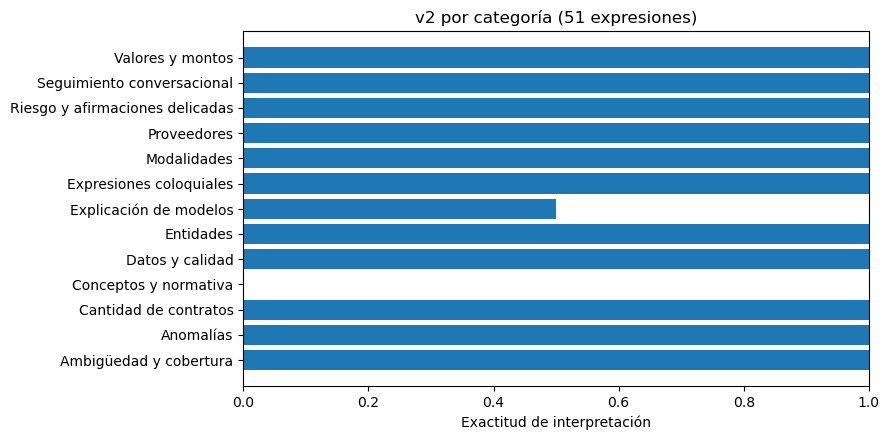

In [10]:
if v2["bloqueo"]:
    print("Sin v2.")
else:
    res2 = v2["resultados"]
    cmp_ = v2["metricas"]["comparacion_v1"]
    print("Corregidos", cmp_["corregidos"])
    print("Regresiones", cmp_["regresiones"])
    display(v2["por_categoria"])
    display(res2[res2["id"].isin(cmp_["corregidos"] + cmp_["regresiones"])][
        ["id", "pregunta", "tipo_respuesta", "interpretacion_ok", "riesgo_enganoso", "texto"]
    ])
    fig_dir = SALIDAS / "figuras"
    fig_dir.mkdir(parents=True, exist_ok=True)
    por = v2["por_categoria"]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(por["categoria"], por["exactitud"])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Exactitud de interpretación")
    ax.set_title("v2 por categoría (51 expresiones)")
    fig.tight_layout()
    fig.savefig(fig_dir / "exactitud_categoria_v2.png", dpi=120)
    plt.show()
